# ETH и экспоненциальные алгоритмы: подробно, на Python и на FPGA

*English version: [`eth_alg_learn_en.ipynb`](eth_alg_learn_en.ipynb).*

Ноутбук разбирает, почему задачи вроде 3-SAT и Subset Sum требуют экспоненциального времени,
что именно утверждает **гипотеза экспоненциального времени (ETH)**, как алгоритмы уменьшают
**основание** экспоненты и что может, а что не может сделать с экспонентой **FPGA**.

Каждое утверждение проверяется тремя способами: **математический вывод → эксперимент на Python →
Verilog-модель, запущенная в Icarus Verilog**.

| Раздел | О чём |
|---|---|
| 1 | Экспонента как стена: почему ускорение в S раз даёт только +log S к размеру задачи |
| 2 | 3-SAT, ETH, SETH, лемма о разрежении, фазовый переход |
| 3 | Ветвление и рекурренты: откуда берутся 1.839ⁿ, 1.466ⁿ |
| 4 | Перебор → бэктрекинг → ветвление по клаузе → DPLL: измеряем основание |
| 5 | Алгоритм Шёнинга: вывод (4/3)ⁿ и эксперимент |
| 6 | Subset Sum: перебор, код Грея, meet-in-the-middle (2ⁿ → 1.414ⁿ) |
| 7 | FPGA: параллельный перебор 3-SAT (`sat_brute.v`) |
| 8 | FPGA: движок Subset Sum в коде Грея (`ss_engine.v`), мультиплексор против LUTRAM |
| 9 | FPGA правильно: DPLL на ARM + BCP за такт в PL (`bcp_unit.v`) |
| 10 | Сводная картина и граница ETH |
| 11 | Упражнения |

Целевое железо: **Zynq-7010 (XC7Z010), плата 7Z-Lite, кварц 50 МГц**:
17 600 LUT6, 35 200 FF, 2.1 Мбит BRAM.

In [1]:
import sys, os, math, time, random
sys.path.insert(0, os.path.abspath('..'))
import numpy as np
import matplotlib.pyplot as plt
import pycosat

from ethlearn import sat, recurrence as rc, subset_sum as ss, fpga

plt.rcParams.update({'figure.figsize': (8, 4.5), 'axes.grid': True, 'grid.alpha': .3})
os.makedirs('../figures', exist_ok=True)
print('iverilog доступен:', fpga.have_iverilog())

iverilog доступен: True


## 1. Экспонента как стена

### 1.1 Любая экспонента — это степень двойки
$$c^n = 2^{n\log_2 c}.$$
Алгоритм со временем $c^n$ ведёт себя как полный перебор **$n\log_2 c$ двоичных переменных**.
Например, $1.307^n = 2^{0.386n}$: лучший известный алгоритм для 3-SAT «перебирает» около 39%
переменных. Уменьшить основание значит уменьшить долю переменных, которые реально нужно перебрать.

### 1.2 Теорема о константном ускорении
Пусть за отведённое время $t$ алгоритм с временем $c^n$ на машине со скоростью $r$ операций/с
решает задачи размера до $n_0$: $c^{n_0} = rt$. Ускорим машину в $S$ раз:
$$c^{n_1} = S\,r\,t = S\,c^{n_0}\;\Rightarrow\; n_1 = n_0 + \log_c S.$$

**Вывод:** ускорение в $S$ раз (FPGA, кластер, следующее поколение CPU) **прибавляет** к
допустимому размеру $\log_c S$, а не умножает его. Для $c=2$:
- ×1000 → +10 переменных;
- ×10⁶ → +20 переменных.

А **алгоритм** с меньшим основанием $c' < c$ **умножает** допустимый размер:
$$c'^{n_1} = c^{n_0} \Rightarrow n_1 = n_0\,\frac{\ln c}{\ln c'}.$$
Например, переход с $2^n$ на $1.414^n$ (meet-in-the-middle) удваивает $n$, а с $2^n$ на $1.307^n$ — умножает на 2.59.

In [2]:
rate = 1e9  # операций в секунду
print(f"{'n':>4} | {'2^n':>10} | {'время при 1e9/с':>22} | {'1.307^n (PPSZ)':>22}")
for n in [20, 30, 40, 50, 60, 80, 100]:
    print(f"{n:>4} | {2.0**n:>10.2e} | {fpga.fmt_time(2.0**n/rate):>22} | {fpga.fmt_time(1.307**n/rate):>22}")

   n |        2^n |        время при 1e9/с |         1.307^n (PPSZ)
  20 |   1.05e+06 |                 1.0 мс |               211.6 нс
  30 |   1.07e+09 |                  1.1 с |                3.1 мкс
  40 |   1.10e+12 |               18.3 мин |               44.8 мкс
  50 |   1.13e+15 |                13.0 дн |              651.3 мкс
  60 |   1.15e+18 |               36.5 лет |                 9.5 мс
  80 |   1.21e+24 |           3.83e+07 лет |                  2.0 с
 100 |   1.27e+30 | 2.91e+03 × возраст Вселенной |                7.1 мин


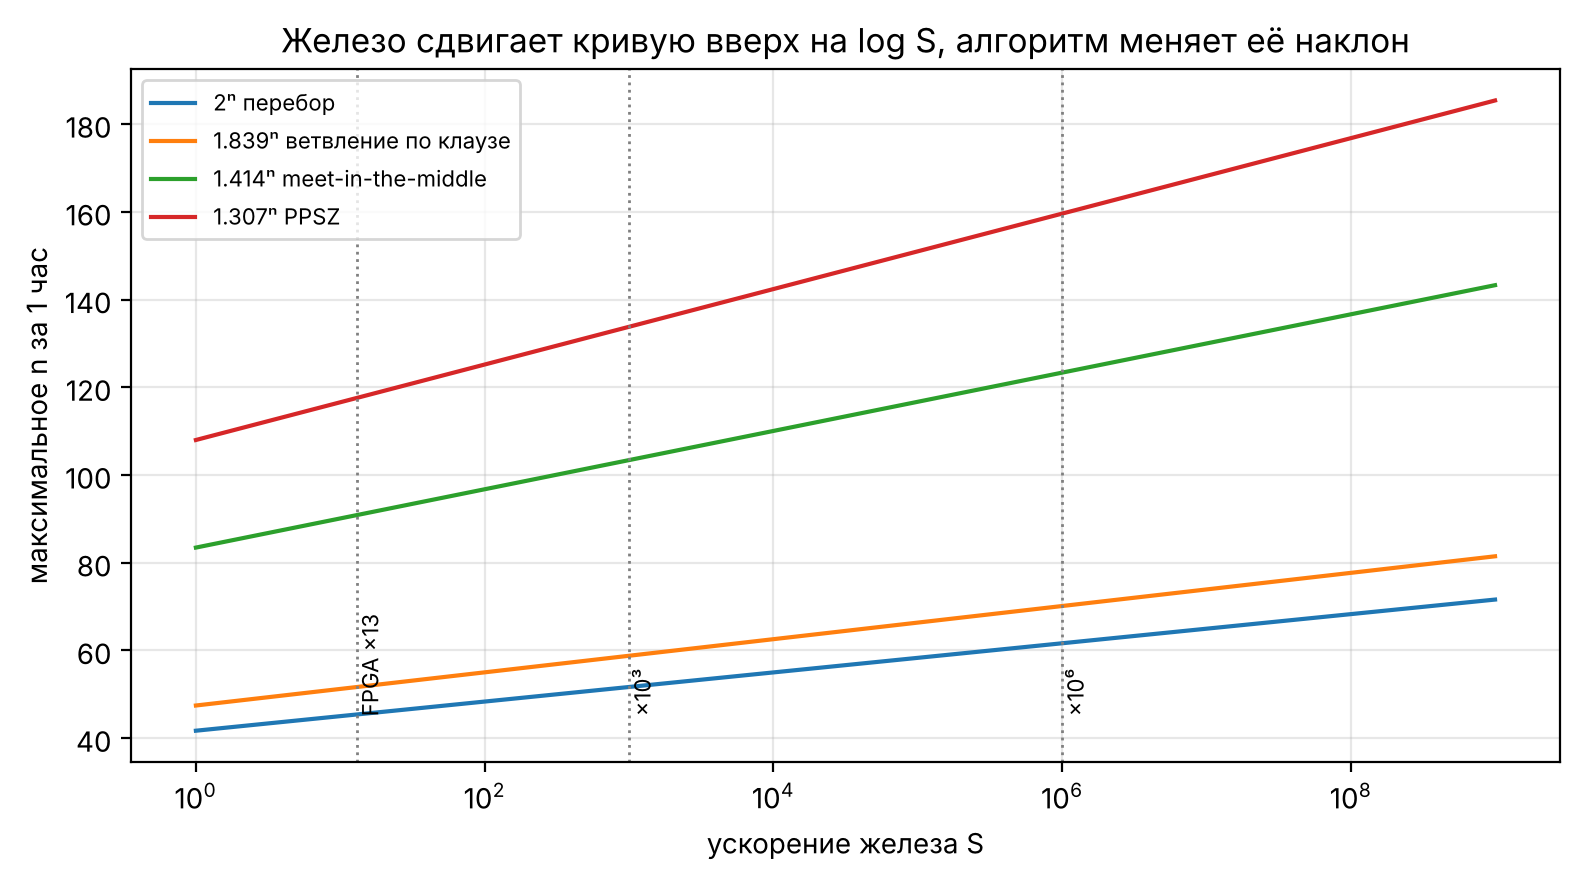

S =        13: +3.7 переменных при 2ⁿ, +9.6 при 1.307ⁿ
S =      1000: +10.0 переменных при 2ⁿ, +25.8 при 1.307ⁿ
S =   1000000: +19.9 переменных при 2ⁿ, +51.6 при 1.307ⁿ


In [3]:
# Какое n решается за 1 час при разном ускорении S и разных основаниях c
S = np.logspace(0, 9, 200)
budget = 3600 * 1e9            # 1 час на 1e9 оп/с
fig, ax = plt.subplots()
for c, name in [(2, '2ⁿ перебор'), (1.839, '1.839ⁿ ветвление по клаузе'),
                (1.414, '1.414ⁿ meet-in-the-middle'), (1.307, '1.307ⁿ PPSZ')]:
    ax.semilogx(S, np.log(budget * S) / np.log(c), label=name)
for s, lab in [(13, 'FPGA ×13'), (1e3, '×10³'), (1e6, '×10⁶')]:
    ax.axvline(s, color='gray', ls=':', lw=1); ax.text(s, 45, lab, rotation=90, va='bottom', fontsize=8)
ax.set_xlabel('ускорение железа S'); ax.set_ylabel('максимальное n за 1 час')
ax.set_title('Железо сдвигает кривую вверх на log S, алгоритм меняет её наклон'); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig('../figures/01_wall.png', dpi=110); plt.show()

for S_ in [13, 1e3, 1e6]:
    print(f"S = {S_:>9.0f}: +{fpga.extra_vars(S_, 2):.1f} переменных при 2ⁿ, "
          f"+{fpga.extra_vars(S_, 1.307):.1f} при 1.307ⁿ")

## 2. 3-SAT и гипотеза экспоненциального времени

### 2.1 Задача
Формула в 3-КНФ — конъюнкция $m$ клауз, каждая клауза — дизъюнкция трёх литералов ($x_i$ или $\neg x_i$).
Вопрос: существует ли назначение $x\in\{0,1\}^n$, выполняющее все клаузы?

- 3-SAT NP-полна (Кук–Левин 1971, Карп 1972);
- 2-SAT решается за $O(n+m)$: клауза $(a\lor b)$ эквивалентна импликациям $\neg a\to b$, $\neg b\to a$,
  и формула невыполнима тогда и только тогда, когда $x$ и $\neg x$ лежат в одной компоненте сильной связности.
  Между 2 и 3 скачок от линейного времени к экспоненциальному.

### 2.2 Формулировки
**ETH (Импальяццо–Патури, 1999).** Существует $\delta>0$, такое что 3-SAT нельзя решить за $O(2^{\delta n})$.
Эквивалентно: $s_3 > 0$, где
$$s_k = \inf\{\delta : k\text{-SAT решается за } O(2^{\delta n})\}.$$
Известно, что $s_3 \le s_4 \le \dots \le 1$; лучшие известные алгоритмы дают $s_3 \le \log_2 1.307 \approx 0.386$.

**SETH.** $\lim_{k\to\infty} s_k = 1$: для любого $\varepsilon>0$ найдётся $k$, при котором $k$-SAT
не решается за $O(2^{(1-\varepsilon)n})$. Иначе говоря, для широких клауз перебор почти оптимален.

### 2.3 Лемма о разрежении (Sparsification Lemma)
Для любого $\varepsilon>0$ формулу $k$-КНФ можно за $2^{\varepsilon n}\cdot\mathrm{poly}(n)$ превратить
в дизъюнкцию $t\le 2^{\varepsilon n}$ формул, у каждой из которых $m = O(n)$ клауз,
причём исходная формула выполнима тогда и только тогда, когда выполнима хотя бы одна из них.

Отсюда ETH эквивалентна утверждению «3-SAT нельзя решить за $2^{o(m)}$», то есть по числу **клауз**.
Это важно, потому что стандартные редукции раздувают размер пропорционально $m$, а не $n$.

### 2.4 Как ETH даёт нижние оценки для других задач
Если редукция переводит 3-SAT с $m$ клаузами в задачу размера $N = O(m)$ (линейная редукция),
то алгоритм за $2^{o(N)}$ для этой задачи дал бы $2^{o(m)}$ для 3-SAT, что противоречит ETH. Так получаются:

| Задача | Нижняя оценка при ETH | Почему |
|---|---|---|
| 3-раскраска графа на $N$ вершинах | $2^{\Omega(N)}$ | гаджет на клаузу — $O(1)$ вершин |
| Vertex Cover, Independent Set, Clique | $2^{\Omega(N)}$ | линейная редукция |
| Гамильтонов цикл | $2^{\Omega(N)}$ | линейная редукция |
| $k$-Clique | нет $f(k)\,N^{o(k)}$ | редукция Чена и др. |
| Задачи на планарных графах | $2^{\Omega(\sqrt N)}$ | гаджеты пересечений дают $N = O(m^2)$ |
| Subset Sum с $n$ числами | $2^{\Omega(n)}$, но $n\log$ бит | линейная редукция по $n$ |

### 2.5 Фазовый переход
Для случайных формул с $m=\alpha n$ вероятность выполнимости резко падает около $\alpha\approx4.27$.
Именно там формулы труднее всего: при малом $\alpha$ решение легко найти, при большом легко доказать невыполнимость.
Проверим это экспериментально.

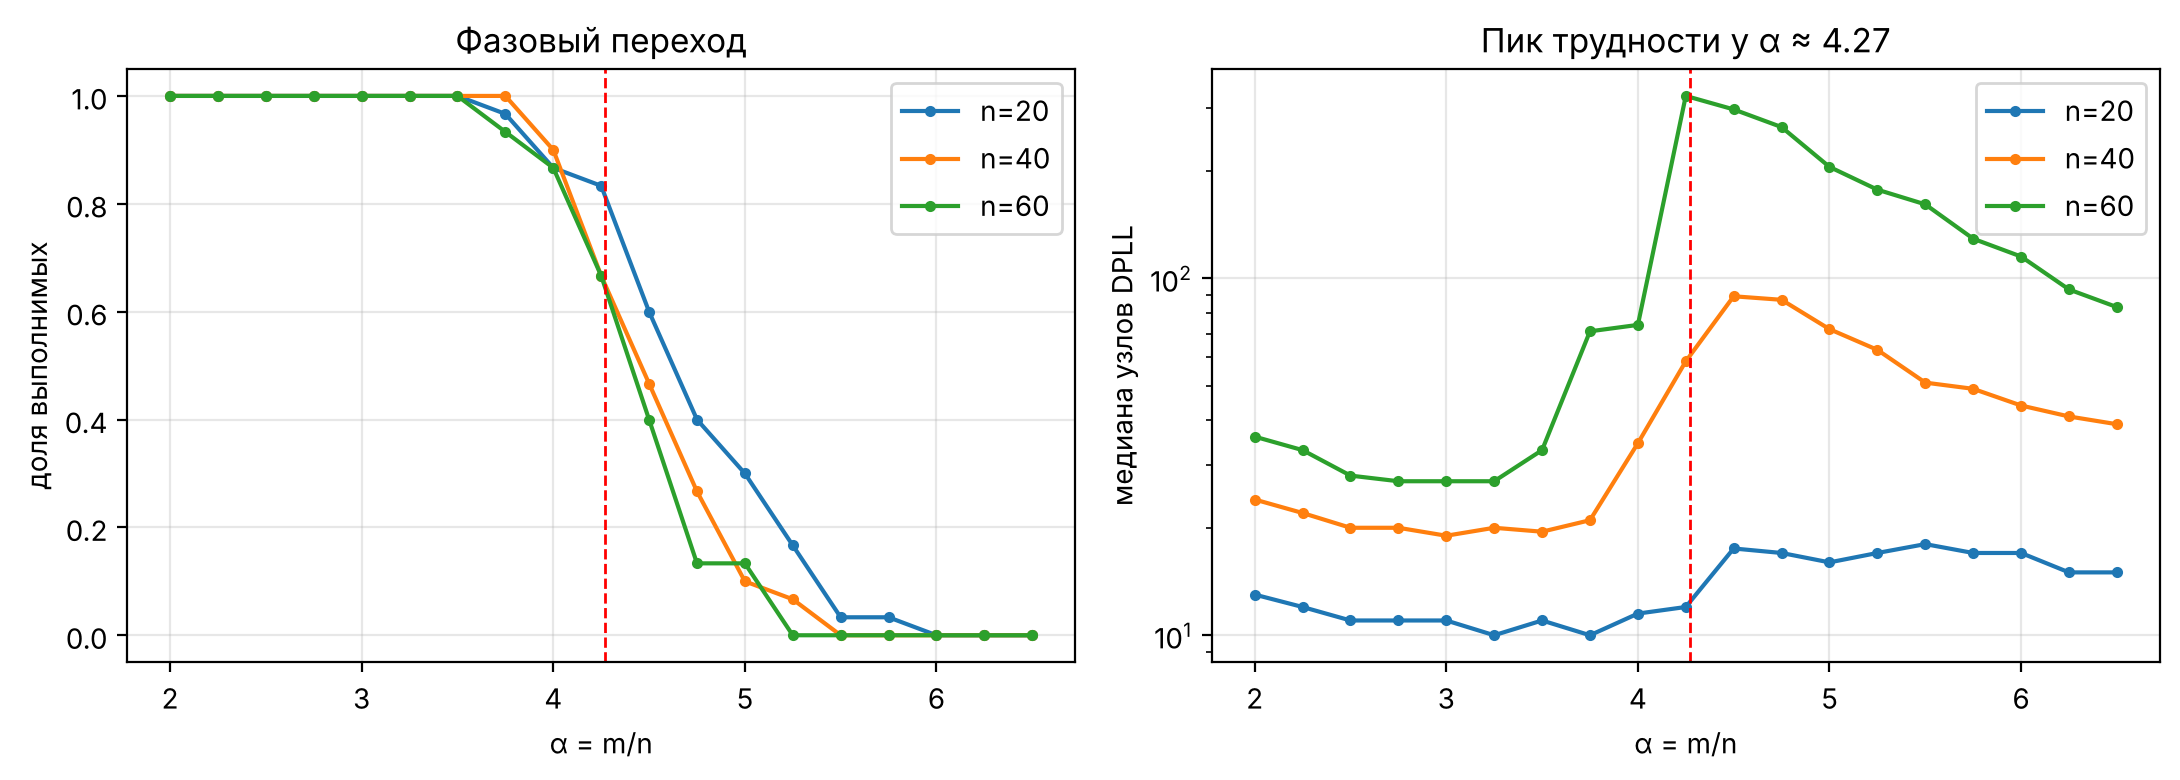

In [4]:
alphas = np.arange(2.0, 6.51, 0.25)
res = {}
for n in [20, 40, 60]:
    p_sat, nodes = [], []
    for a_ in alphas:
        s_cnt, nd = 0, []
        for seed in range(30 if n < 60 else 15):
            cnf = sat.random_3sat_ratio(n, a_, seed=10_000 * n + seed)
            x, st = sat.dpll(cnf, n)
            s_cnt += x is not None
            nd.append(st['nodes'])
        p_sat.append(s_cnt / (30 if n < 60 else 15)); nodes.append(np.median(nd))
    res[n] = (p_sat, nodes)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
for n, (p, nd) in res.items():
    a1.plot(alphas, p, 'o-', ms=3, label=f'n={n}')
    a2.semilogy(alphas, nd, 'o-', ms=3, label=f'n={n}')
for a in (a1, a2): a.axvline(4.27, color='r', ls='--', lw=1); a.set_xlabel('α = m/n'); a.legend()
a1.set_ylabel('доля выполнимых'); a1.set_title('Фазовый переход')
a2.set_ylabel('медиана узлов DPLL'); a2.set_title('Пик трудности у α ≈ 4.27')
fig.tight_layout(); fig.savefig('../figures/02_phase.png', dpi=110); plt.show()

**Что видно:** с ростом $n$ переход становится всё круче, а пик трудности стоит у $\alpha\approx4.27$.
Дальше все эксперименты со случайными формулами делаются при $\alpha=4.27$.

## 3. Ветвление и рекурренты: откуда берутся основания

### 3.1 Общий метод
Рекурсивный алгоритм на задаче «размера» $n$ (число свободных переменных) делает полиномиальную работу
и вызывает себя на подзадачах размеров $n-d_1,\dots,n-d_r$. Число листьев дерева
$$T(n) = T(n-d_1)+\dots+T(n-d_r).$$
Ищем решение вида $T(n)=c^n$ и делим на $c^n$:
$$\boxed{\;1 = c^{-d_1}+c^{-d_2}+\dots+c^{-d_r}\;}\qquad(*)$$
Левая часть при $c>1$ строго убывает от $r$ до $0$, поэтому корень $c>1$ единственный.
Это **branching number** вектора ветвления $(d_1,\dots,d_r)$. Умножив $(*)$ на $c^D$, $D=\max d_i$,
получаем характеристический многочлен линейной рекурренты $c^D-\sum c^{D-d_i}=0$;
$c$ — его наибольший положительный корень.

**Строго:** по индукции $T(n)\le c^n$, если $T(k)\le c^k$ для $k<n$:
$T(n)\le\sum c^{n-d_i}=c^n\sum c^{-d_i}=c^n$.

### 3.2 Примеры
| Алгоритм | Ветви | Вектор $d$ | $c$ |
|---|---|---|---|
| Перебор: $x=0$ или $x=1$ | 2 | (1,1) | 2 |
| 3-SAT, ветвление по клаузе $(l_1\lor l_2\lor l_3)$: $l_1{=}1$ / $l_1{=}0,l_2{=}1$ / $l_1{=}0,l_2{=}0,l_3{=}1$ | 3 | (1,2,3) | 1.839 |
| То же, но клауза уже двухлитеральная | 2 | (1,2) | 1.618 (золотое сечение) |
| Независимое множество, вершина степени ≥ 2: не брать $v$ / взять $v$ и выкинуть соседей | 2 | (1,3) | 1.466 |
| Vertex Cover размера $k$ по ребру $(u,v)$: взять $u$ / взять $v$ | 2 | (1,1) по $k$ | $2^k$ |
| Vertex Cover, вершина степени ≥ 3: взять $v$ / взять все $N(v)$ | 2 | (1,3) по $k$ | $1.466^k$ |

**Почему ветвление по клаузе корректно:** три ветви взаимоисключающие и вместе покрывают все
выполняющие назначения клаузы (7 из 8 комбинаций $l_1l_2l_3$; комбинация 000 клаузу не выполняет).
Перебор тратит ветви и на 000, отсюда выигрыш.

In [5]:
cases = {
    'перебор (1,1)': [1, 1],
    'клауза из 3 (1,2,3)': [1, 2, 3],
    'клауза из 2 (1,2)': [1, 2],
    'независимое множество (1,3)': [1, 3],
    'IS, степень 3: (1,4)': [1, 4],
    '4-SAT по клаузе (1,2,3,4)': [1, 2, 3, 4],
}
print(f"{'вектор':32} {'c (бисекция)':>13} {'c (корни многочлена)':>21} {'log2 c':>8}")
for name, d in cases.items():
    c = rc.branching_number(d)
    roots = rc.char_poly_roots(d)
    cmax = max(r.real for r in roots if abs(r.imag) < 1e-9)
    print(f"{name:32} {c:13.6f} {cmax:21.6f} {rc.log2_base(c):8.3f}")

вектор                            c (бисекция)  c (корни многочлена)   log2 c
перебор (1,1)                         2.000000              2.000000    1.000
клауза из 3 (1,2,3)                   1.839287              1.839287    0.879
клауза из 2 (1,2)                     1.618034              1.618034    0.694
независимое множество (1,3)           1.465571              1.465571    0.551
IS, степень 3: (1,4)                  1.380278              1.380278    0.465
4-SAT по клаузе (1,2,3,4)             1.927562              1.927562    0.947


Заметим: $k$-SAT при ветвлении по клауз даёт вектор $(1,2,\dots,k)$, и корень стремится к 2
при $k\to\infty$. Это простая иллюстрация SETH: при широких клаузах тривиальное ветвление почти не лучше
перебора. Проверим и сходимость самой рекурренты: $T(n+1)/T(n)\to c$.

In [6]:
T = rc.unroll([1, 2, 3], 40)
for n in [5, 10, 20, 30, 40]:
    print(f"n={n:2d}  T(n)={T[n]:>14,}  T(n)/T(n-1)={T[n]/T[n-1]:.6f}")
print('c =', rc.branching_number([1, 2, 3]))

n= 5  T(n)=            31  T(n)/T(n-1)=1.823529
n=10  T(n)=           653  T(n)/T(n-1)=1.839437
n=20  T(n)=       289,329  T(n)/T(n-1)=1.839287
n=30  T(n)=   128,199,521  T(n)/T(n-1)=1.839287
n=40  T(n)=56,804,250,945  T(n)/T(n-1)=1.839287
c = 1.8392867552144407


## 4. От перебора к DPLL: измеряем основание экспериментально

Четыре решателя на одних и тех же формулах ($\alpha=4.27$):

1. **Перебор** — назначения $0,1,2,\dots$ по возрастанию, счётчик проверенных назначений. Худший случай $2^n$.
2. **Бэктрекинг** — дерево $x_1,x_2,\dots$ с отсечением ветки, как только какая-то клауза стала ложной.
3. **Ветвление по клаузе** (Монин–Шпеккенмейер) — ветвимся по самой короткой невыполненной клаузе. Оценка $1.839^n$.
4. **DPLL** — unit propagation (если в клаузе остался один свободный литерал, он обязан быть истинным) + ветвление.

Основание оценивается регрессией $\log_2(\text{работа}) \approx a + b\,n$, тогда $c = 2^b$.
Для случайных формул измеренные основания **меньше** худшего случая: оценка рекуррентой — верхняя граница,
а на случайных формулах клаузы быстро укорачиваются.

время экспериментов: 31 с


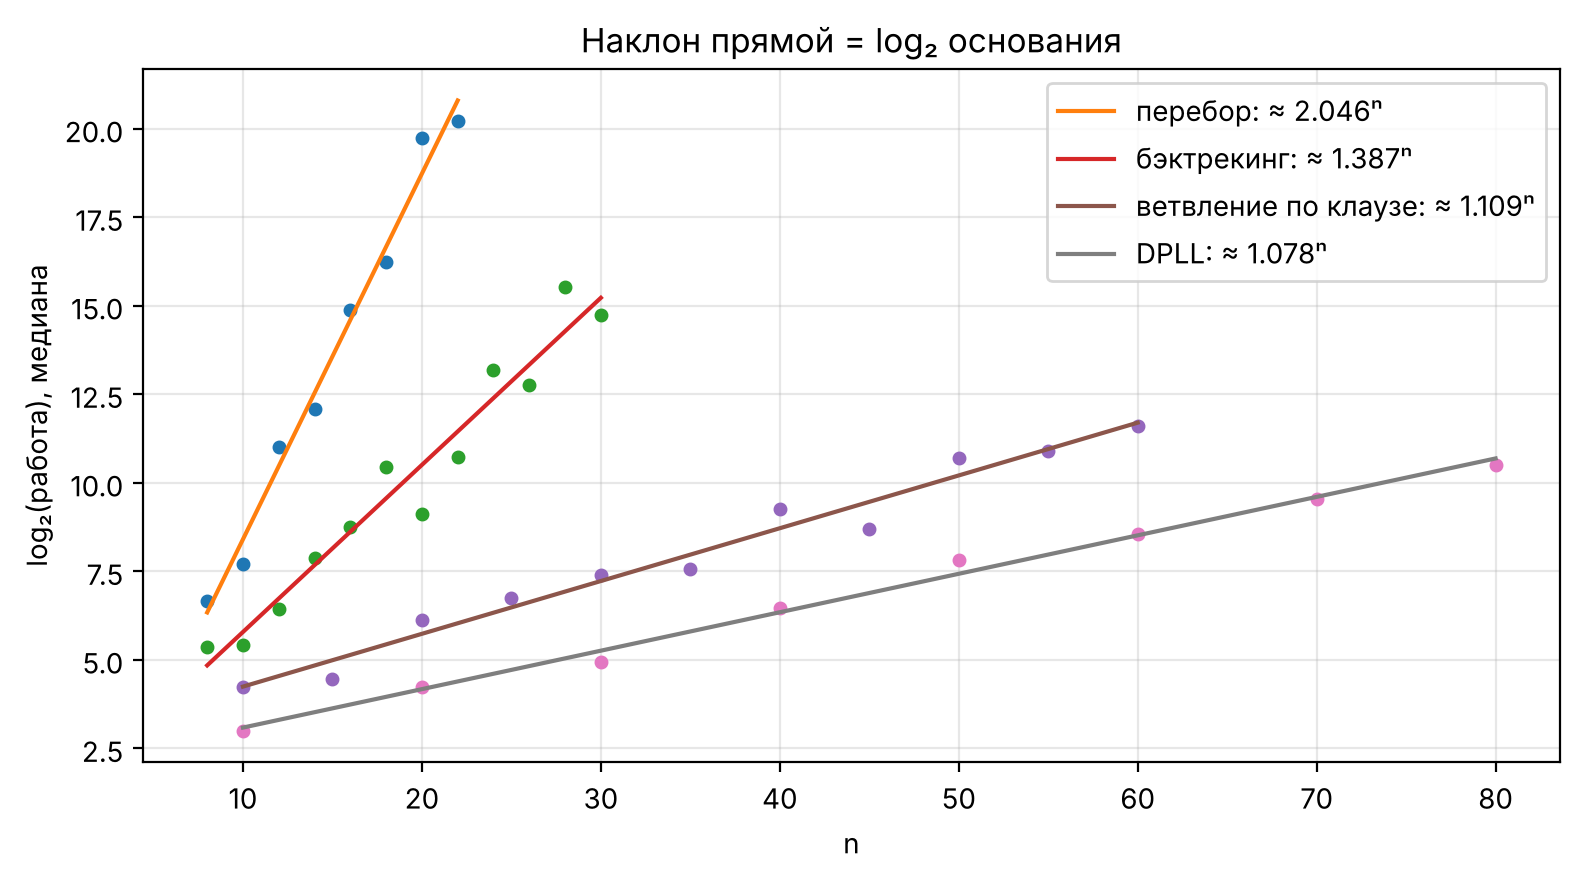

перебор                c ≈ 2.046   (2^1.033 n)
бэктрекинг             c ≈ 1.387   (2^0.472 n)
ветвление по клаузе    c ≈ 1.109   (2^0.149 n)
DPLL                   c ≈ 1.078   (2^0.109 n)


In [7]:
def measure(solver, ns, seeds, key):
    out = []
    for n in ns:
        vals = [solver(sat.random_3sat_ratio(n, 4.27, seed=777 * n + s), n)[1][key] for s in range(seeds)]
        out.append(np.median(vals))
    return np.array(out, float)

t0 = time.time()
ns_bf = np.arange(8, 23, 2);  w_bf = measure(sat.brute_force, ns_bf, 9, 'checked')
ns_bt = np.arange(8, 31, 2);  w_bt = measure(sat.backtracking, ns_bt, 9, 'nodes')
ns_cb = np.arange(10, 61, 5); w_cb = measure(sat.clause_branching, ns_cb, 9, 'nodes')
ns_dp = np.arange(10, 81, 10); w_dp = measure(sat.dpll, ns_dp, 9, 'nodes')
print(f'время экспериментов: {time.time()-t0:.0f} с')

fits = {}
fig, ax = plt.subplots()
for name, ns_, w in [('перебор', ns_bf, w_bf), ('бэктрекинг', ns_bt, w_bt),
                     ('ветвление по клаузе', ns_cb, w_cb), ('DPLL', ns_dp, w_dp)]:
    b, a = np.polyfit(ns_, np.log2(w), 1)
    fits[name] = 2 ** b
    ax.plot(ns_, np.log2(w), 'o', ms=4)
    ax.plot(ns_, a + b * ns_, '-', label=f'{name}: ≈ {2**b:.3f}ⁿ')
ax.set_xlabel('n'); ax.set_ylabel('log₂(работа), медиана'); ax.legend()
ax.set_title('Наклон прямой = log₂ основания')
fig.tight_layout(); fig.savefig('../figures/04_bases.png', dpi=110); plt.show()
for k, v in fits.items(): print(f'{k:22s} c ≈ {v:.3f}   (2^{math.log2(v):.3f} n)')

**Как читать результат.**
- Перебор на невыполнимых формулах проверяет все $2^n$, на выполнимых до первого решения. Медиана растёт с основанием около 2.
- Бэктрекинг уже заметно лучше: отсечение по ложной клаузе срезает целые поддеревья.
- Ветвление по самой короткой клаузе почти всегда выбирает клаузу из 1–2 литералов, то есть фактически делает unit propagation.
- DPLL на случайных 3-SAT даёт основание около $1.05$–$1.1$. Это **не противоречит** ETH:
  ETH говорит о **худшем случае**, а у случайных формул есть структура, которую DPLL использует.
  На специально построенных формулах (например, принцип Дирихле) DPLL экспоненциален с заметным основанием.

Главное: никакое из этих улучшений не получено ускорением железа. Это **меньше работы**, а не та же работа быстрее.

## 5. Алгоритм Шёнинга: рандомизация даёт $(4/3)^n$

**Алгоритм** (Шёнинг, 1999). Повторять:
1. взять случайное $x\in\{0,1\}^n$;
2. $3n$ раз: если $x$ выполняет формулу — успех; иначе взять любую невыполненную клаузу
   и перевернуть **случайную** из её трёх переменных.

**Анализ.** Пусть $x^*$ — какое-то решение, $j$ — расстояние Хэмминга от $x$ до $x^*$.
В невыполненной клаузе $x^*$ выполняет хотя бы один литерал, а $x$ — ни одного,
значит хотя бы одна из трёх переменных клаузы отличается от $x^*$. Случайный переворот уменьшает $j$
с вероятностью $\ge 1/3$ и увеличивает с вероятностью $\le 2/3$.

Вероятность случайным блужданием дойти от $j$ до 0 за $3j$ шагов, сделав $j$ шагов «назад» и $2j$ «вперёд»,
не меньше
$$\binom{3j}{j}\left(\tfrac{2}{3}\right)^{j}\left(\tfrac{1}{3}\right)^{2j}\;\approx\;\frac{1}{\mathrm{poly}(j)}\cdot 2^{-j}.$$
(По Стирлингу $\binom{3j}{j}\approx(27/4)^j$, и $(27/4)^j(2/27)^j=2^{-j}$.)

Начальное расстояние $j\sim\mathrm{Bin}(n,1/2)$, поэтому вероятность успеха одной попытки
$$p \ge \frac{1}{\mathrm{poly}(n)}\sum_{j=0}^{n}\binom{n}{j}2^{-n}\,2^{-j}
=\frac{1}{\mathrm{poly}(n)}\left(\frac{1+1/2}{2}\right)^n=\frac{1}{\mathrm{poly}(n)}\left(\frac34\right)^n.$$
Ожидаемое число попыток $1/p=\mathrm{poly}(n)\,(4/3)^n$, то есть $2^{0.415n}$.
Для $k$-SAT тот же расчёт даёт $\left(2(1-1/k)\right)^n$: снова стремится к $2^n$ при $k\to\infty$.

Проверим на трудных выполнимых формулах ($\alpha=4.2$, близко к порогу).

2 с


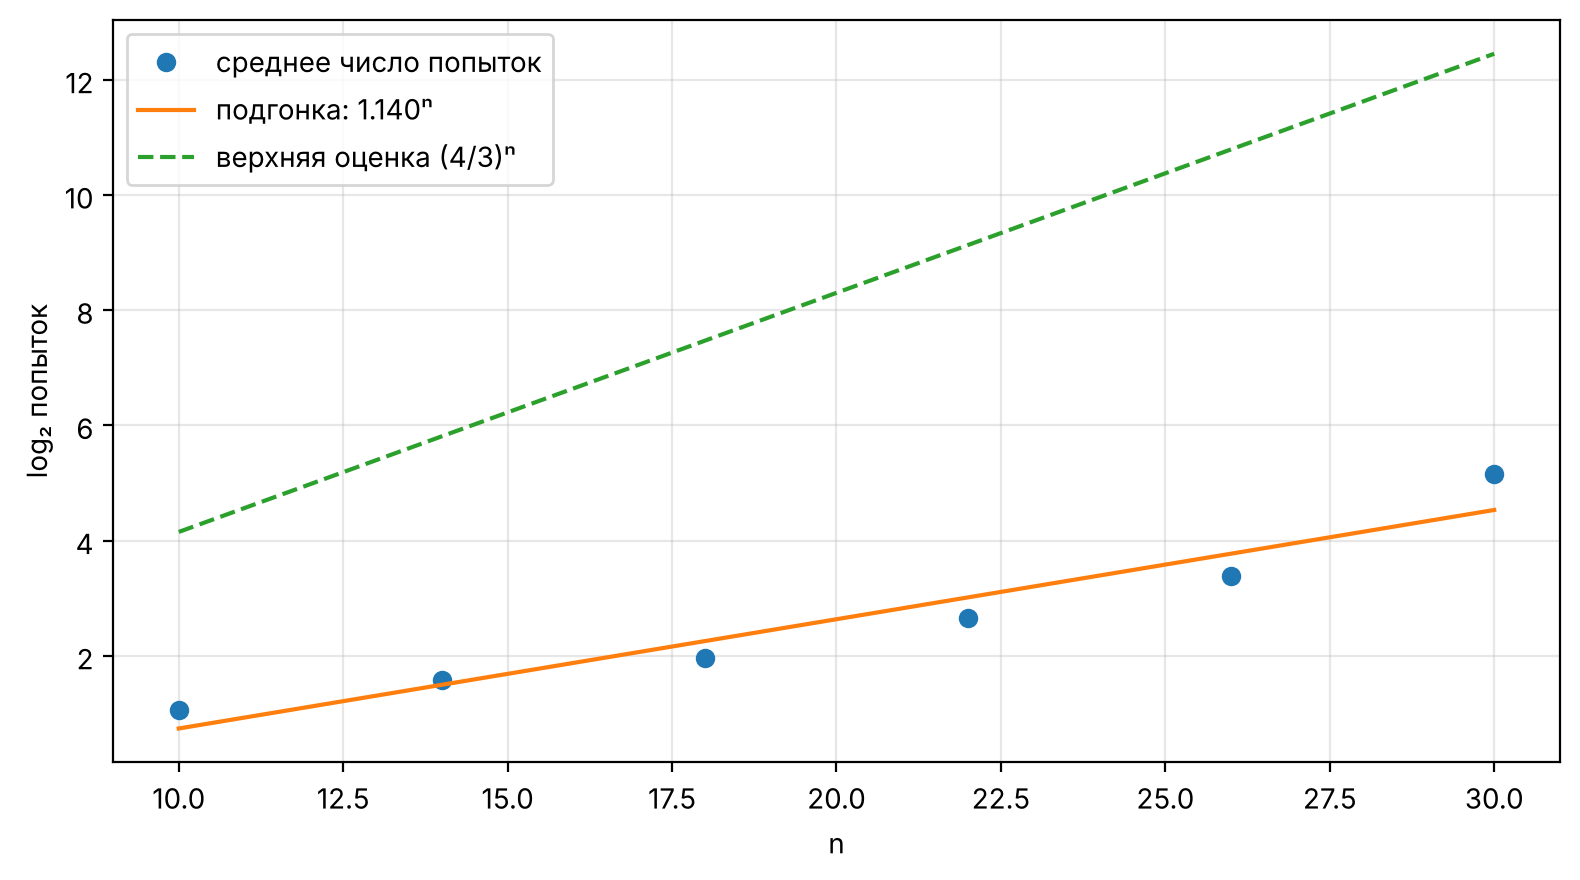

In [8]:
def sch_experiment(ns, per_n=12, alpha=4.2):
    med = []
    for n in ns:
        tries, s = [], 0
        while len(tries) < per_n:
            cnf = sat.random_ksat(n, int(alpha * n), 3, seed=50_000 + 1000 * n + s); s += 1
            if pycosat.solve([list(c) for c in cnf]) == 'UNSAT':
                continue
            x, st = sat.schoening(cnf, n, seed=s)
            assert x is not None and sat.satisfies(cnf, x)
            tries.append(st['tries'])
        med.append(np.mean(tries))
    return np.array(med)

ns_s = np.arange(10, 31, 4)
t0 = time.time(); tr = sch_experiment(ns_s); print(f'{time.time()-t0:.0f} с')
b, a = np.polyfit(ns_s, np.log2(tr), 1)
fig, ax = plt.subplots()
ax.plot(ns_s, np.log2(tr), 'o', label='среднее число попыток')
ax.plot(ns_s, a + b * ns_s, '-', label=f'подгонка: {2**b:.3f}ⁿ')
ax.plot(ns_s, ns_s * math.log2(4 / 3), '--', label='верхняя оценка (4/3)ⁿ')
ax.set_xlabel('n'); ax.set_ylabel('log₂ попыток'); ax.legend()
fig.tight_layout(); fig.savefig('../figures/05_schoening.png', dpi=110); plt.show()

На случайных формулах попыток нужно **намного меньше**, чем $(4/3)^n$: у них много решений,
а оценка рассчитана на худший случай с одним решением. Смысл анализа в **гарантии**:
вероятность успеха попытки не меньше $(3/4)^n/\mathrm{poly}(n)$ для **любой** выполнимой формулы.

Цепочка улучшений для 3-SAT в худшем случае:

| Год | Алгоритм | Время |
|---|---|---|
| — | перебор | $2^n$ |
| 1985 | Монин–Шпеккенмейер | $1.619^n$ |
| 1999 | Шёнинг (рандом.) | $1.334^n$ |
| 2005 | PPSZ (Патури, Пудлак, Сакс, Зейн) | $1.308^n$ |
| 2011–2021 | Хертли; Хансен–Каплан–Замир–Цвик | $\approx1.307^n$ |

Основание уменьшается всё медленнее. ETH утверждает, что к 1 его не свести.

## 6. Subset Sum: три уровня перебора

Даны $a_0,\dots,a_{n-1}$ и $T$; найти маску $S$ с $\sum_{i\in S}a_i=T$.

### 6.1 Наивный перебор: $O(n\cdot2^n)$
Для каждой из $2^n$ масок заново складываем до $n$ чисел.

### 6.2 Код Грея: $O(2^n)$
Рефлексивный код Грея $g(i)=i\oplus(i\gg1)$ обходит все маски так, что соседние отличаются **одним** битом.

**Какой бит меняется.** $g(i)\oplus g(i-1) = (i\oplus(i-1)) \oplus ((i\oplus(i-1))\gg1)$.
Число $i\oplus(i-1)$ имеет вид $0\dots01\dots1$ с $t+1$ единицами, где $t=\mathrm{ctz}(i)$ (число младших нулей $i$).
После XOR со сдвигом остаётся одна единица в позиции $t$. Итак:
$$\text{на шаге } i \text{ меняется бит } \mathrm{ctz}(i),\quad\text{новое значение } g(i)_{\mathrm{ctz}(i)}.$$
Если бит стал 1, элемент вошёл в подмножество: $s \mathrel{+}= a_{\mathrm{ctz}(i)}$; если стал 0 — вышел: $s \mathrel{-}= a_{\mathrm{ctz}(i)}$.
Одно сложение на маску. Это ровно то, что делает `ss_engine.v`.

In [9]:
print(f"{'i':>2} {'bin(i)':>7} {'ctz':>4} {'g(i)':>6} {'dir':>4}  действие")
for i in range(1, 16):
    t = (i & -i).bit_length() - 1
    g = i ^ (i >> 1)
    d = g >> t & 1
    print(f"{i:>2} {i:07b} {t:>4} {g:06b} {d:>4}  {'+' if d else '-'}a[{t}]")

 i  bin(i)  ctz   g(i)  dir  действие
 1 0000001    0 000001    1  +a[0]
 2 0000010    1 000011    1  +a[1]
 3 0000011    0 000010    0  -a[0]
 4 0000100    2 000110    1  +a[2]
 5 0000101    0 000111    1  +a[0]
 6 0000110    1 000101    0  -a[1]
 7 0000111    0 000100    0  -a[0]
 8 0001000    3 001100    1  +a[3]
 9 0001001    0 001101    1  +a[0]
10 0001010    1 001111    1  +a[1]
11 0001011    0 001110    0  -a[0]
12 0001100    2 001010    0  -a[2]
13 0001101    0 001011    1  +a[0]
14 0001110    1 001001    0  -a[1]
15 0001111    0 001000    0  -a[0]


### 6.3 Meet-in-the-middle: $O(2^{n/2}\cdot n)$, основание $\sqrt2\approx1.414$
Разбиваем числа на две половины $A$ и $B$ по $n/2$. Любая маска — это пара $(S_A,S_B)$, и
$$\sum S_A + \sum S_B = T \iff \sum S_B = T-\sum S_A.$$
1. Перечислить все $2^{n/2}$ сумм $B$ и отсортировать: $O(2^{n/2}\,n)$;
2. для каждой из $2^{n/2}$ сумм $A$ найти $T-s$ бинарным поиском: $O(2^{n/2}\,n)$.

Итог $2^{n/2}=(\sqrt2)^n$ при памяти $2^{n/2}$ (Горовиц–Сахни, 1974). Шрёппель–Шамир (1981) снижают память
до $2^{n/4}$ при том же времени. Это **алгоритмическое** уменьшение основания: две половины независимы,
поэтому вместо произведения $2^{n/2}\cdot2^{n/2}$ работа складывается: $2^{n/2}+2^{n/2}$.

### 6.4 Псевдополиномиальное ДП: $O(nT)$
Битсет достижимых сумм. Полиномиально по **значению** $T$, но экспоненциально по **длине записи** $\log T$.
С ETH это не конфликтует: задача трудна, когда числа имеют $\Theta(n)$ бит.

In [10]:
rows = []
for n in [12, 16, 20, 24]:
    a, T = ss.random_instance(n, bits=40, solvable=False, seed=n)   # решения нет -> полный обход
    r = {'n': n}
    if n <= 20:
        t0 = time.time(); _, st = ss.naive(a, T); r['naive_adds'] = st['adds']; r['naive_s'] = time.time() - t0
    t0 = time.time(); _, st = ss.gray(a, T); r['gray_adds'] = st['adds']; r['gray_s'] = time.time() - t0
    t0 = time.time(); _, st = ss.meet_in_the_middle(a, T); r['mitm_sums'] = st['sums']; r['mitm_s'] = time.time() - t0
    rows.append(r)
print(f"{'n':>3} | {'наивно, сложений':>17} {'с':>6} | {'Грей':>10} {'с':>6} | {'MitM, сумм':>10} {'с':>6}")
for r in rows:
    nv = f"{r['naive_adds']:>17,} {r['naive_s']:6.2f}" if 'naive_adds' in r else f"{'—':>17} {'':>6}"
    print(f"{r['n']:>3} | {nv} | {r['gray_adds']:>10,} {r['gray_s']:6.2f} | {r['mitm_sums']:>10,} {r['mitm_s']:6.3f}")

# проверка корректности на выполнимых примерах
for seed in range(20):
    a, T = ss.random_instance(16, bits=30, seed=seed)
    for f in (ss.gray, ss.meet_in_the_middle):
        m, _ = f(a, T); assert m is not None and ss.mask_sum(a, m) == T
print('все решения проверены')

  n |  наивно, сложений      с |       Грей      с | MitM, сумм      с
 12 |            24,576   0.00 |      4,095   0.00 |        128  0.000
 16 |           524,288   0.06 |     65,535   0.01 |        512  0.000
 20 |        10,485,760   1.16 |  1,048,575   0.19 |      2,048  0.002
 24 |                 —        | 16,777,215   2.34 |      8,192  0.007
все решения проверены


**Цифры:** код Грея убирает множитель $n$, MitM при $n=24$ перебирает 8 192 суммы вместо 16.7 млн.
Экстраполяция на $n=60$ при $10^9$ операций/с: перебор $2^{60}$ — 36 лет; MitM $2\cdot2^{30}\cdot60$ — пара минут,
но таблица $2^{30}$ сумм занимает 8–16 ГБ. Шрёппель–Шамир при том же времени держит в памяти около $2^{15}$ записей.

## 7. FPGA №1: параллельный перебор 3-SAT (`rtl/sat_brute.v`)

### 7.1 Как клауза становится логикой
Клауза хранится двумя масками: `pos` (литералы $x_i$) и `neg` (литералы $\neg x_i$). Назначение $a$ её выполняет, если
$$\bigl((a\,\&\,\mathrm{pos}) \mid (\sim a\,\&\,\mathrm{neg})\bigr)\neq0.$$
Маски — константы (из `$readmemh`), поэтому синтез сворачивает каждую клаузу в одну функцию **трёх** бит
назначения, то есть в 1 LUT6, а всю формулу — в дерево AND. Проверка **всех** $m$ клауз занимает один такт.

### 7.2 Параллельность
$P=2^{\text{LOGP}}$ одинаковых ядер. Ядро $k$ проверяет назначение $a=\{\text{cnt},k\}$: младшие LOGP бит
зашиты в ядро константой, старшие задаёт общий счётчик. Константы упрощают клаузы с младшими переменными
(литерал либо сразу истинен — клауза исчезает, либо выпадает из клаузы), так что ядра даже меньше.

```
cnt ──► [P копий формулы] ──► ok[P-1:0] ──► [приоритетный шифратор] ──► solution = cnt·P + k
```
Полный перебор: $2^n/P$ тактов. Назначения идут по возрастанию, поэтому найденное — **минимальное**
выполняющее назначение, и его можно сверить с `sat.brute_force`.

In [11]:
print(open('../rtl/sat_brute.v').read()[:2400])

// sat_brute.v — параллельный перебор 3-SAT: P = 2^LOGP ядер, каждое за такт целиком
// проверяет одно назначение (все M клауз параллельно).
//
// Клауза = две маски: pos (литералы x_i) и neg (литералы ¬x_i).
// Назначение a выполняет клаузу <=> |((a & pos) | (~a & neg)).
// Ядро k проверяет назначение a = {cnt, k}; полный перебор — 2^(N-LOGP) тактов.
// Назначения идут по возрастанию, поэтому найденное решение — минимальное.
// (Расширенная версия для платы с UART: fpga-course/sat-bruteforce.)
module sat_brute #(
    parameter N     = 16,
    parameter M     = 68,
    parameter LOGP  = 2,
    parameter PFILE = "pos.mem",
    parameter NFILE = "neg.mem"
) (
    input  wire          clk,
    input  wire          rst,
    input  wire          start,
    output reg           done,
    output reg           sat,
    output reg  [N-1:0]  solution,
    output reg  [47:0]   cycles
);
    localparam P  = 1 << LOGP;
    localparam CW = N - LOGP;

    reg [N-1:0] pos [0:M-1];
    reg [N-1:0] neg 

In [12]:
# Прогон в Icarus Verilog: сверка с Python и рост числа тактов
n = 14
s = 0
while True:                       # берём выполнимую формулу у порога
    cnf_sat = sat.random_3sat_ratio(n, 4.0, seed=300 + s); s += 1
    x_ref, st = sat.brute_force(cnf_sat, n)
    if x_ref is not None and st['checked'] > 2000:
        break
ref_int = sum(b << i for i, b in enumerate(x_ref)) if x_ref else None
print('Python: минимальное решение', ref_int, 'проверено', st['checked'])
for logp in range(0, 5):
    r = fpga.sim_sat(cnf_sat, n, logp)
    ok = r['sat'] and r['x'] == ref_int
    print(f"LOGP={logp} P={2**logp:2d}: решение={r['x']:6d} тактов={r['cycles']:6d}  "
          f"ожидалось ≈ {math.ceil(st['checked'] / 2**logp):6d}  {'OK' if ok else 'FAIL'}")

Python: минимальное решение 11605 проверено 11606


LOGP=0 P= 1: решение= 11605 тактов= 11606  ожидалось ≈  11606  OK


LOGP=1 P= 2: решение= 11605 тактов=  5803  ожидалось ≈   5803  OK


LOGP=2 P= 4: решение= 11605 тактов=  2902  ожидалось ≈   2902  OK


LOGP=3 P= 8: решение= 11605 тактов=  1451  ожидалось ≈   1451  OK


LOGP=4 P=16: решение= 11605 тактов=   726  ожидалось ≈    726  OK


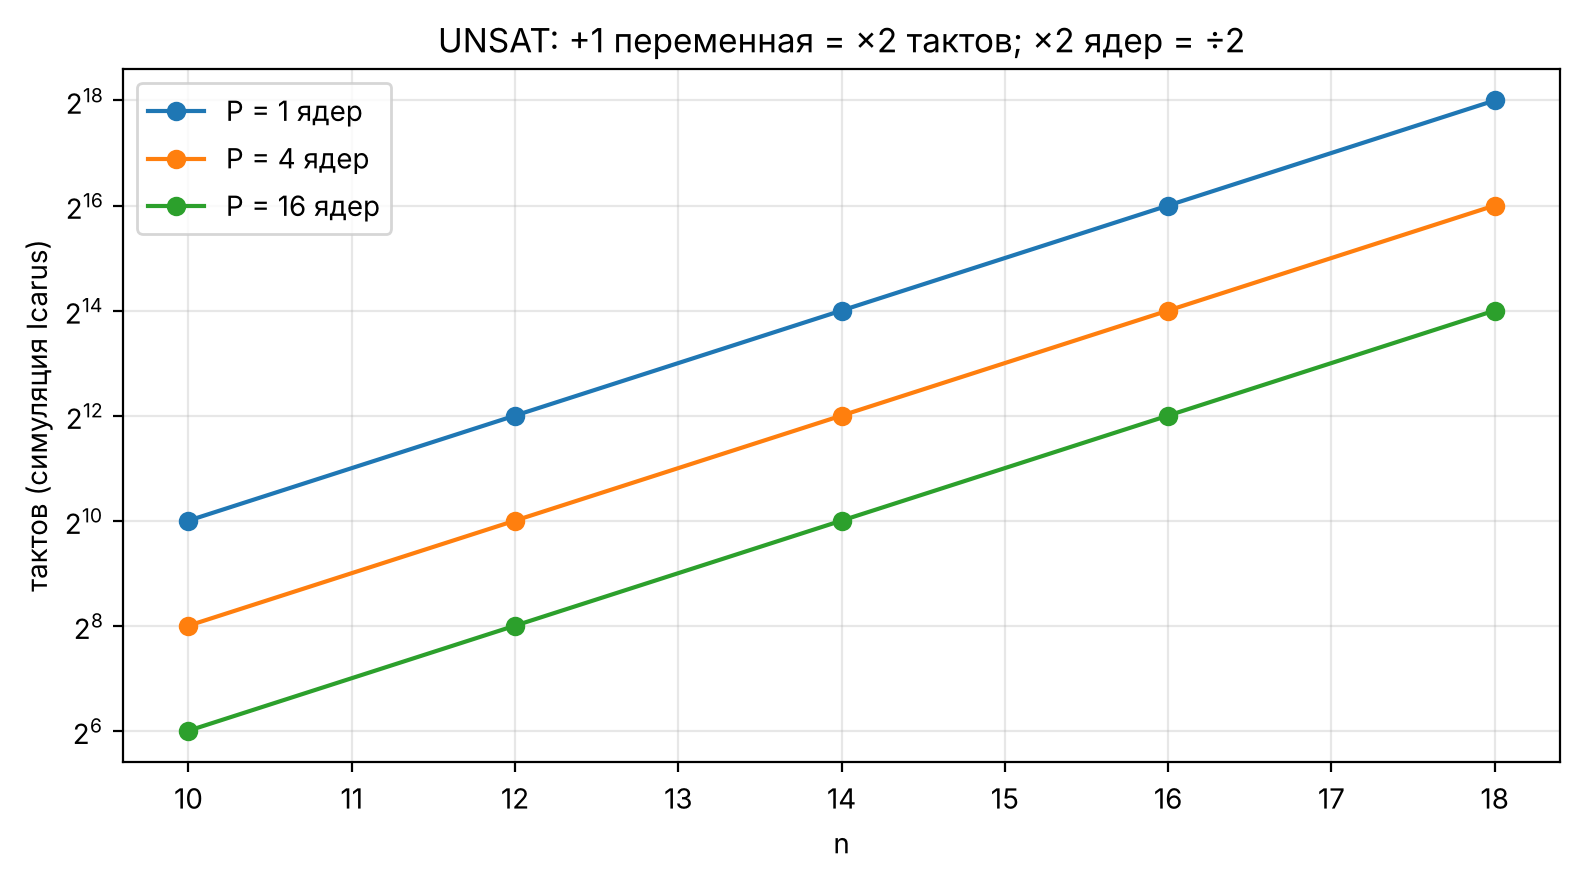

P= 1: [1024, 4096, 16384, 65536, 262144]  2^(n-LOGP) = [1024, 4096, 16384, 65536, 262144]
P= 4: [256, 1024, 4096, 16384, 65536]  2^(n-LOGP) = [256, 1024, 4096, 16384, 65536]
P=16: [64, 256, 1024, 4096, 16384]  2^(n-LOGP) = [64, 256, 1024, 4096, 16384]


In [13]:
# Невыполнимые формулы: чистая экспонента 2^(n-LOGP)
unsat_cnfs = {}
for n in range(10, 19, 2):
    s = 0
    while True:
        cnf = sat.random_3sat_ratio(n, 6.0, seed=900 + 37 * n + s); s += 1
        if pycosat.solve([list(c) for c in cnf]) == 'UNSAT':
            unsat_cnfs[n] = cnf; break
cyc = {}
for logp in [0, 2, 4]:
    cyc[logp] = [fpga.sim_sat(unsat_cnfs[n], n, logp)['cycles'] for n in unsat_cnfs]
ns_u = list(unsat_cnfs)
fig, ax = plt.subplots()
for logp, c in cyc.items():
    ax.semilogy(ns_u, c, 'o-', base=2, label=f'P = {2**logp} ядер')
ax.set_xlabel('n'); ax.set_ylabel('тактов (симуляция Icarus)'); ax.legend()
ax.set_title('UNSAT: +1 переменная = ×2 тактов; ×2 ядер = ÷2')
fig.tight_layout(); fig.savefig('../figures/07_sat_cycles.png', dpi=110); plt.show()
for logp, c in cyc.items():
    print(f'P={2**logp:2d}:', c, ' 2^(n-LOGP) =', [2**(n - logp) for n in ns_u])

### 7.3 Сколько ядер помещается в XC7Z010 и что это даёт
Ядро на $m$ клауз ≈ $m$ LUT (клаузы) + $m/5$ (дерево AND). При $n=40$, $m=171$ это ~205 LUT,
то есть около 68 ядер на 80% от 17 600 LUT. Счётчик идёт на все ядра (большой fanout), поэтому
реалистичная частота — 50–100 МГц.

In [14]:
for n in [32, 40, 48, 60]:
    m = round(4.27 * n)
    core = fpga.sat_core_cost(m)
    P = 2 ** int(math.log2(core.fit()))
    for f in [50e6, 100e6]:
        rate = P * f
        print(f"n={n} m={m}: ядро ~{core.lut} LUT, P={P}, {f/1e6:.0f} МГц -> {rate:.1e} назн./с; "
              f"полный перебор {fpga.fmt_time(2**n / rate)}; CPU (1e8/с) {fpga.fmt_time(2**n / 1e8)}; "
              f"выигрыш +{fpga.extra_vars(rate / 1e8):.1f} перем.")

n=32 m=137: ядро ~165 LUT, P=64, 50 МГц -> 3.2e+09 назн./с; полный перебор 1.3 с; CPU (1e8/с) 42.9 с; выигрыш +5.0 перем.
n=32 m=137: ядро ~165 LUT, P=64, 100 МГц -> 6.4e+09 назн./с; полный перебор 671.1 мс; CPU (1e8/с) 42.9 с; выигрыш +6.0 перем.
n=40 m=171: ядро ~206 LUT, P=64, 50 МГц -> 3.2e+09 назн./с; полный перебор 5.7 мин; CPU (1e8/с) 3.1 ч; выигрыш +5.0 перем.
n=40 m=171: ядро ~206 LUT, P=64, 100 МГц -> 6.4e+09 назн./с; полный перебор 2.9 мин; CPU (1e8/с) 3.1 ч; выигрыш +6.0 перем.
n=48 m=205: ядро ~246 LUT, P=32, 50 МГц -> 1.6e+09 назн./с; полный перебор 2.0 дн; CPU (1e8/с) 32.6 дн; выигрыш +4.0 перем.
n=48 m=205: ядро ~246 LUT, P=32, 100 МГц -> 3.2e+09 назн./с; полный перебор 1.0 дн; CPU (1e8/с) 32.6 дн; выигрыш +5.0 перем.
n=60 m=256: ядро ~308 LUT, P=32, 50 МГц -> 1.6e+09 назн./с; полный перебор 22.8 лет; CPU (1e8/с) 365 лет; выигрыш +4.0 перем.
n=60 m=256: ядро ~308 LUT, P=32, 100 МГц -> 3.2e+09 назн./с; полный перебор 11.4 лет; CPU (1e8/с) 365 лет; выигрыш +5.0 перем.


## 8. FPGA №2: движок Subset Sum в коде Грея (`rtl/ss_engine.v`, `rtl/ss_array.v`)

### 8.1 Один движок — одно подмножество за такт
Регистр `sum` хранит сумму для маски $g(\text{cnt})$. За такт параллельно:
- компаратор `sum == T`;
- следующая сумма `sum + delta`, где `delta` — приращение для бита $\mathrm{ctz}(\text{cnt}+1)$.

### 8.2 Ошибка эскиза и правильный выбор приращения
В первом эскизе стояло `sum + (gray_next[bit] ? a[bit] : -a[bit])`. Это мультиплексор $N{:}1$ шириной $W$:
около 10 LUT на бит при $N=32$, то есть ~400 LUT только на выбор, и 64 движка не помещаются.

Решение: заранее посчитать таблицу из $2N$ слов
$$\mathrm{dtab}[\{\mathrm{idx},\mathrm{dir}\}] = \begin{cases}+a_{\mathrm{idx}}, & \mathrm{dir}=1\\ -a_{\mathrm{idx}}, & \mathrm{dir}=0\end{cases}$$
и положить её в распределённую RAM. `RAM64X1` хранит 64 однобитных слова в **одном** LUT6, поэтому таблица
до 64 слов стоит $W$ LUT. Заодно исчезает выбор знака.

### 8.3 Деление между движками
Маска $=\{k,\text{low}\}$: старшие $K$ элементов закреплены за движком $k$ (их сумма — константа `base[k]`),
младшие $N_L=N-K$ каждый движок перебирает сам. $P=2^K$ движков проходят всё за $2^{N-K}$ тактов.

In [15]:
print(open('../rtl/ss_engine.v').read())

// ss_engine.v — один движок Subset Sum: перебор 2^NL подмножеств в коде Грея,
// одно подмножество за такт.
//
// Маска в такте cnt:   g(cnt) = cnt ^ (cnt >> 1)
// Переход cnt -> cnt+1 меняет ровно один бит маски: idx = ctz(cnt+1).
// Новое значение этого бита dir = g(cnt+1)[idx]:
//     dir = 1 -> элемент вошёл в подмножество:  sum += a[idx]
//     dir = 0 -> элемент вышел:                 sum -= a[idx]
//
// Вместо мультиплексора a[idx] (NL:1 шириной W ≈ 10 LUT/бит) приращение берётся из
// таблицы dtab[{idx,dir}] = dir ? +a[idx] : -a[idx]. Таблица на 2*NL <= 64 слова
// ложится в распределённую RAM: RAM64X1 = 1 LUT на бит, то есть ~W LUT на движок.
//
// base — сумма «старших» элементов, закреплённых за этим движком (см. ss_array.v).
module ss_engine #(
    parameter NL    = 10,              // сколько элементов перебирает движок
    parameter W     = 40,              // разрядность сумм
    parameter DFILE = "dtab.mem"       // 2*NL слов: [2*i] = -a[i], [2*i+1] = +a[i]
) (
    inp

In [16]:
# Сверка с Python на выполнимых и невыполнимых примерах
for (n, K, solv, seed) in [(14, 0, True, 1), (14, 2, True, 2), (16, 3, True, 3), (16, 4, True, 4),
                           (14, 2, False, 5), (16, 3, False, 6)]:
    a, T = ss.random_instance(n, bits=30, solvable=solv, seed=seed)
    r = fpga.sim_subset_sum(a, T, K)
    ok = (r['found'] and ss.mask_sum(a, r['mask']) == T) or (not solv and not r['found'])
    print(f"n={n} K={K} P={2**K:2d} {'SAT  ' if solv else 'UNSAT'} -> found={int(r['found'])} "
          f"mask={r['mask']:#07x} тактов={r['cycles']:6d} (полный обход {2**(n-K)})  {'OK' if ok else 'FAIL'}")

n=14 K=0 P= 1 SAT   -> found=1 mask=0x0327b тактов=  9135 (полный обход 16384)  OK
n=14 K=2 P= 4 SAT   -> found=1 mask=0x013b9 тактов=   723 (полный обход 4096)  OK


n=16 K=3 P= 8 SAT   -> found=1 mask=0x04266 тактов=   957 (полный обход 8192)  OK


n=16 K=4 P=16 SAT   -> found=1 mask=0x0c3e2 тактов=   702 (полный обход 4096)  OK


n=14 K=2 P= 4 UNSAT -> found=0 mask=0x00000 тактов=  4097 (полный обход 4096)  OK


n=16 K=3 P= 8 UNSAT -> found=0 mask=0x00000 тактов=  8193 (полный обход 8192)  OK


In [17]:
# Ресурсы: мультиплексор против LUTRAM, сколько движков помещается и какая скорость
print(f"{'вариант':22} {'N_L':>4} {'W':>3} {'LUT/движок':>11} {'движков':>8}")
for NL in [16, 26, 32]:
    for lutram in (False, True):
        c = fpga.ss_engine_cost(NL, 40, lutram)
        print(f"{c.name:22} {NL:>4} {40:>3} {c.lut:>11} {c.fit():>8}")
print()
for n in [40, 50, 60]:
    c = fpga.ss_engine_cost(n - 6, 48, True)
    P = 2 ** int(math.log2(c.fit()))
    for f in [100e6, 200e6]:
        rate = P * f
        print(f"n={n}: P={P}, {f/1e6:.0f} МГц -> {rate:.2e} масок/с, перебор {fpga.fmt_time(2**n/rate)}; "
              f"CPU-Грей (1e9/с) {fpga.fmt_time(2**n/1e9)}; MitM на CPU ~{fpga.fmt_time(2*2**(n/2)*n/1e9)}")

вариант                 N_L   W  LUT/движок  движков
ss_engine (mux)          16  40         278       50
ss_engine (LUTRAM)       16  40         118      119
ss_engine (mux)          26  40         533       26
ss_engine (LUTRAM)       26  40         133      105
ss_engine (mux)          32  40         542       25
ss_engine (LUTRAM)       32  40         142       99

n=40: P=64, 100 МГц -> 6.40e+09 масок/с, перебор 2.9 мин; CPU-Грей (1e9/с) 18.3 мин; MitM на CPU ~83.9 мс
n=40: P=64, 200 МГц -> 1.28e+10 масок/с, перебор 1.4 мин; CPU-Грей (1e9/с) 18.3 мин; MitM на CPU ~83.9 мс
n=50: P=32, 100 МГц -> 3.20e+09 масок/с, перебор 4.1 дн; CPU-Грей (1e9/с) 13.0 дн; MitM на CPU ~3.4 с
n=50: P=32, 200 МГц -> 6.40e+09 масок/с, перебор 2.0 дн; CPU-Грей (1e9/с) 13.0 дн; MitM на CPU ~3.4 с
n=60: P=32, 100 МГц -> 3.20e+09 масок/с, перебор 11.4 лет; CPU-Грей (1e9/с) 36.5 лет; MitM на CPU ~2.1 мин
n=60: P=32, 200 МГц -> 6.40e+09 масок/с, перебор 5.71 лет; CPU-Грей (1e9/с) 36.5 лет; MitM на CPU ~2.1 ми

**Итог раздела.** При $n=40$ помещается 64 движка; на 200 МГц это $1.3\cdot10^{10}$ масок/с, примерно ×13 к
одному ядру CPU, то есть **+3.7 переменной**. При $n\ge50$ таблица приращений перестаёт помещаться в один
RAM64X1 и влезает 32 движка. Meet-in-the-middle на том же CPU удваивает $n$: при $n=60$ FPGA-перебор
занимает почти 6 лет, а MitM — пару минут.

FPGA полезна и для MitM, но иначе: PL генерирует суммы половин по коду Грея (каждый движок — поток сумм),
а ARM их сортирует и сливает. Ограничение — память: $2^{n/2}$ записей не помещаются в 2.1 Мбит BRAM,
поэтому нужна DDR или вариант Шрёппеля–Шамира с памятью $2^{n/4}$.

> Оценки ресурсов здесь модельные. Точные цифры покажет `utilization.rpt` после синтеза в Vivado.
> Критический путь движка: `cnt → +1 → ctz → LUTRAM → 40-битный сумматор`. Для 200 МГц его конвейеризуют:
> idx и delta считают на такт раньше (они зависят только от cnt).

## 9. FPGA №3, правильное применение: DPLL на ARM + BCP за такт (`rtl/bcp_unit.v`)

Разделы 7–8 показали: параллельный перебор даёт **константу**. Правильная связка — сначала уменьшить основание
алгоритмом (DPLL/CDCL), а потом ускорить его самый частый шаг.

**BCP (Boolean Constraint Propagation)** — проход по всем клаузам при частичном назначении: найти конфликт
(все литералы клаузы ложны) или unit-клаузу (нет истинных и ровно один свободный литерал).
В CDCL-солверах на него уходит 80–90% времени.

На FPGA каждая клауза — отдельная маленькая схема от `assigned`/`value` своих трёх переменных:
$$\text{T}=\text{asg}\wedge(\text{val}\oplus s),\quad \text{F}=\text{asg}\wedge\neg(\text{val}\oplus s),\quad \text{U}=\neg\text{asg}$$
$$\text{sat}=\bigvee \text{T},\quad \text{conflict}=\bigwedge \text{F},\quad \text{unit}=\neg\text{sat}\wedge(\#\text{U}=1).$$
Все $m$ клауз считаются **одновременно**, за такт, а не за $m$ шагов CPU.

### 9.1 Проверка: трасса настоящего DPLL против Verilog
Запускаем `sat.dpll` с записью каждого частичного назначения, на котором он делал проход по клаузам, подаём
эти же назначения в `bcp_unit.v` и сверяем ответы.

In [18]:
n = 16
cnf = sat.random_3sat_ratio(n, 4.27, seed=7)
trace = []
x, st = sat.dpll(cnf, n, trace=trace)
print('DPLL:', 'SAT' if x else 'UNSAT', st, 'записано состояний:', len(trace))
hw = fpga.sim_bcp(cnf, n, trace)
mism = 0
for (asg, val), h in zip(trace, hw):
    ref = fpga.bcp_reference(cnf, n, asg, val)
    same = h[:3] == ref[:3] and (not ref[2] or h[3:] == ref[3:])
    mism += not same
from collections import Counter
print('расхождений с Python:', mism, 'из', len(hw))
print('исходы (conflict, all_sat, unit):', Counter(h[:3] for h in hw))

DPLL: SAT {'nodes': 13, 'bcp_rounds': 36, 'clause_checks': 2448} записано состояний: 36
расхождений с Python: 0 из 36
исходы (conflict, all_sat, unit): Counter({(0, 0, 1): 23, (0, 0, 0): 10, (1, 0, 0): 2, (0, 1, 0): 1})


### 9.2 Сколько это даёт
Модель времени DPLL: $\;t = R\cdot t_{\text{BCP}} + \text{остальное}$, где $R$ — число проходов BCP.

- CPU: $t_{\text{BCP}}\approx m\cdot 5$ нс (проход по $m$ клаузам с переходами по памяти).
- FPGA: $t_{\text{BCP}} = 1$ такт, но если ARM дёргает PL на каждый проход через AXI-GP, добавляется
  ~0.3–1 мкс задержки шины. Поэтому на практике в PL переносят весь цикл распространения
  (присвоить unit-литерал → снова BCP → …), а ARM получает только итог: конфликт или новая точка ветвления.

In [19]:
ns_b = [40, 60, 80]
print(f"{'n':>3} {'узлов':>7} {'проходов BCP':>13} | {'CPU BCP':>10} {'PL+AXI на проход':>17} {'PL цикл целиком':>16}")
for n in ns_b:
    m = round(4.27 * n)
    R, N_ = [], []
    for s in range(7):
        _, st = sat.dpll(sat.random_3sat_ratio(n, 4.27, seed=31 * n + s), n)
        R.append(st['bcp_rounds']); N_.append(st['nodes'])
    R, N_ = np.median(R), np.median(N_)
    cpu = R * m * 5e-9
    pl_axi = R * (1 / 100e6 + 0.5e-6)
    pl_loop = R / 100e6 + N_ * 0.5e-6        # одна транзакция AXI на узел дерева
    print(f"{n:>3} {N_:>7.0f} {R:>13.0f} | {fpga.fmt_time(cpu):>10} {fpga.fmt_time(pl_axi):>17} {fpga.fmt_time(pl_loop):>16}")

  n   узлов  проходов BCP |    CPU BCP  PL+AXI на проход  PL цикл целиком


 40     147           898 |  767.8 мкс         458.0 мкс         82.5 мкс


 60     439          3723 |     4.8 мс            1.9 мс        256.7 мкс


 80     692          6467 |    11.1 мс            3.3 мс        410.7 мкс


**Вывод.** Ускорение BCP — это та же константа, что и в разделах 7–8, но поверх алгоритма с основанием около 1.1
вместо 2. Константа умножается на уже уменьшенную экспоненту. Порядок важен: **сначала основание, потом константа.**

## 10. Сводная картина
Время до решения при разных стратегиях. Основание DPLL измерено в разделе 4 на **случайных** формулах
(это не худший случай); линия PPSZ — гарантированная оценка для **любой** формулы. Скорости — из разделов 7–9.

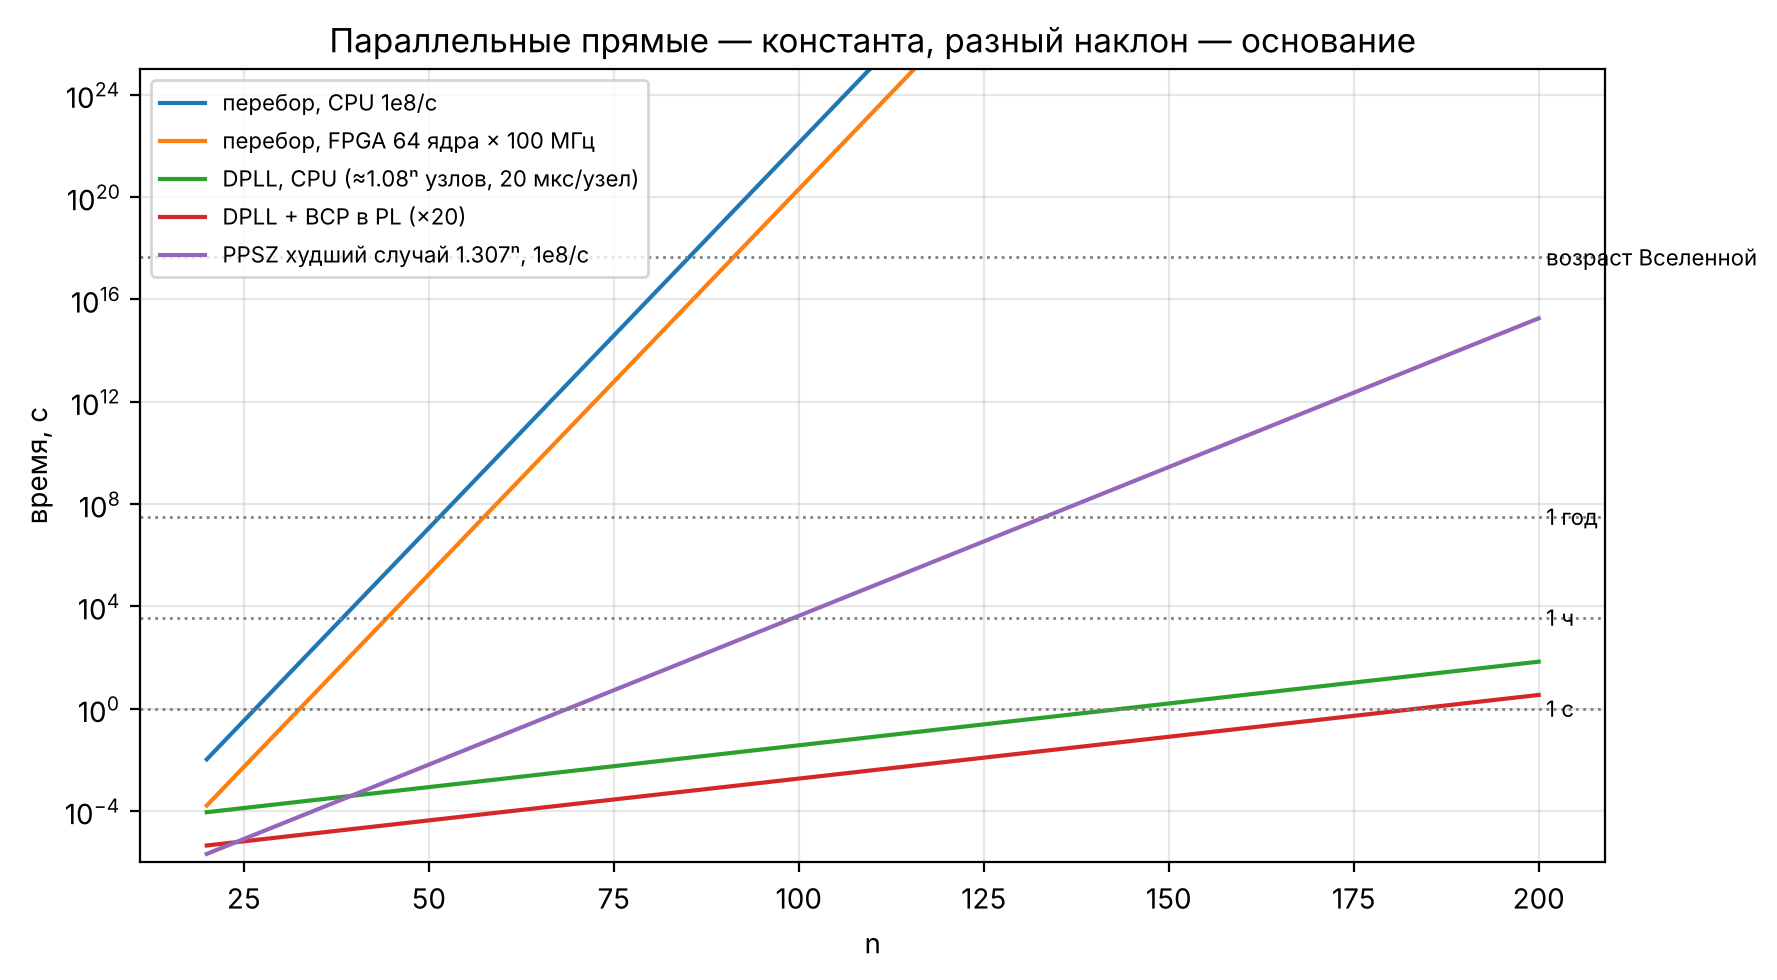

In [20]:
ns_all = np.arange(20, 201)
c_dp = fits['DPLL']
lines = {
    'перебор, CPU 1e8/с':                 2.0 ** ns_all / 1e8,
    'перебор, FPGA 64 ядра × 100 МГц':     2.0 ** ns_all / 6.4e9,
    f'DPLL, CPU (≈{c_dp:.2f}ⁿ узлов, 20 мкс/узел)': c_dp ** ns_all * 20e-6,
    'DPLL + BCP в PL (×20)':               c_dp ** ns_all * 1e-6,
    'PPSZ худший случай 1.307ⁿ, 1e8/с':    1.307 ** ns_all / 1e8,
}
fig, ax = plt.subplots(figsize=(9, 5))
for k, v in lines.items():
    ax.semilogy(ns_all, v, label=k)
for y, lab in [(1, '1 с'), (3600, '1 ч'), (3.156e7, '1 год'), (4.35e17, 'возраст Вселенной')]:
    ax.axhline(y, color='gray', ls=':', lw=1); ax.text(201, y, lab, fontsize=8, va='center')
ax.set_ylim(1e-6, 1e25); ax.set_xlabel('n'); ax.set_ylabel('время, с'); ax.legend(fontsize=8)
ax.set_title('Параллельные прямые — константа, разный наклон — основание')
fig.tight_layout(); fig.savefig('../figures/10_summary.png', dpi=110); plt.show()

### 10.1 Где граница
- **Основание можно уменьшать:** $2\to1.839\to1.619\to1.334\to1.307$ (худший случай 3-SAT).
- **ETH:** нельзя дойти до $2^{o(n)}$, то есть существует $s_3>0$ с временем не меньше $2^{s_3 n}$.
- **SETH:** для широких клауз основание стремится к 2, перебор почти оптимален. Следствия:
  нет $O(N^{2-\varepsilon})$ для edit distance, LCS, Orthogonal Vectors.
- **Железо** не меняет ни $s_3$, ни основание: $P$ ядер — это $\log_2 P$ переменных.

### 10.2 Рецепт для своей задачи
1. Запишите рекурренту текущего перебора, найдите $c$ из $(*)$.
2. Ищите ветвление, где каждая ветвь фиксирует больше переменных.
3. Повторяющиеся подзадачи → мемоизация / ДП по маскам ($n!\to n^2 2^n$).
4. Задача распадается на независимые половины → meet-in-the-middle ($c\to\sqrt c$).
5. Есть малый параметр $k$ → FPT ($c^n\to c^k\,\mathrm{poly}(n)$).
6. Подумайте о рандомизации (Шёнинг).
7. **Только потом** переносите на FPGA самую частую однородную операцию: BCP, генерацию сумм, проверку клауз.

## 11. Упражнения

1. **Рекуррента.** Ветвление по вершине степени $\ge3$ для Independent Set даёт вектор $(1,4)$.
   Посчитайте $c$ через `rc.branching_number` и выведите вручную из характеристического многочлена $c^4-c^3-1=0$.
2. **k-SAT.** Постройте $c(k)$ для ветвления по клаузе $(1,\dots,k)$ и для Шёнинга $2(1-1/k)$ при $k=3..10$.
   С какой скоростью оба стремятся к 2? Свяжите с SETH.
3. **Трудные формулы для DPLL.** Сгенерируйте формулы принципа Дирихле (PHPₙ: $n+1$ голубь, $n$ ящиков)
   и измерьте основание DPLL. Сравните со случайными формулами.
4. **FPGA.** В `ss_engine.v` вынесите `idx`, `dir` и `delta` в конвейерный регистр (они зависят только от `cnt`)
   и проверьте в Icarus, что ответы не изменились. На сколько такт стал короче по логике?
5. **MitM на Zynq.** Оцените, при каком $n$ таблица $2^{n/2}$ сумм по 6 байт перестаёт помещаться в 2.1 Мбит BRAM
   и в 512 МБ DDR. Что даёт вариант Шрёппеля–Шамира?
6. **BCP в железе.** Расширьте `bcp_unit.v` так, чтобы он сам присваивал unit-литерал и повторял проход
   до конфликта или неподвижной точки. Сколько тактов в среднем занимает такой цикл на трассе из раздела 9?